In [ ]:
Data Source: Find an appropriate data source based on the Data Requirements above.

In [ ]:
Data Prep: Break your data into 2 csv files. Use a “key” field that you can use to put them back
together – this may be some type of ID that already exists or you can just create a row ID to use
for this purpose. For example, from the attached two csv data, the customers.csv and the
transactions.csv are linked by the key “customerID”.

In [39]:
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.formula.api import ols

import os
import pandas as pd
import numpy as np

demo_df = pd.read_csv('Cleaned_Students_PerformanceDemographic.csv')

demo_data

score_df = pd.read_csv('Cleaned_Students_PerformanceScore.csv')

score_data

full_df = pd.merge(demo_df, score_df, on="Student Num")

full_df

full_df["gender"] = full_df["gender"].replace({
    0: "Female",
    1: "Male"
})

full_df["lunch"] = full_df["lunch"].replace({
    0: "no free lunch",
    1: "free lunch"
})
full_df["test_preparation_course"] = full_df["test_preparation_course"].replace({
    0: "no",
    1: "yes"
})

full_df

,Student Num,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,total_score,average_score
0,1,Female,group B,bachelor's degree,free lunch,no,72,72,74,218,72.67
1,2,Female,group C,some college,free lunch,yes,69,90,88,247,82.33
2,3,Female,group B,master's degree,free lunch,no,90,95,93,278,92.67
3,4,Male,group A,associate's degree,no free lunch,no,47,57,44,148,49.33
4,5,Male,group C,some college,free lunch,no,76,78,75,229,76.33
...,...,...,...,...,...,...,...,...,...,...,...
995,996,Female,group E,master's degree,free lunch,yes,88,99,95,282,94.00
996,997,Male,group C,high school,no free lunch,no,62,55,55,172,57.33
997,998,Female,group C,high school,no free lunch,yes,59,71,65,195,65.00
998,999,Female,group D,some college,free lunch,yes,68,78,77,223,74.33


In [ ]:
#To List at least 3 research questions that you want to explore with your data.
#These research questions should be able to be answers with either basic 
#descriptive summaries, cross-tabs, or other grouping summaries.
#For this project, you need to have descriptive summaries of all of your columns
#as well as some other grouping summaries or cross-tabs.

RQ 1 : How correlated are reading and writing scores?

RQ 2 : How much better do students do if they are in a prep course?

RQ 3 : What is the hypothetically best conditions for a student to score?

In [40]:
# Intital Summaries

for col in full_df.columns:
    print(f"\nColumn: {col}")
    
    if full_df[col].dtype == 'object':
        print("Qualitative Summary:")
        print(full_df[col].value_counts())
    else:
        print("Quantitative Summary:")
        print(full_df[col].describe())


Column: Student Num
Quantitative Summary:
count    1000.000000
mean      500.500000
std       288.819436
min         1.000000
25%       250.750000
50%       500.500000
75%       750.250000
max      1000.000000
Name: Student Num, dtype: float64

Column: gender
Qualitative Summary:
gender
Female    518
Male      482
Name: count, dtype: int64

Column: race_ethnicity
Qualitative Summary:
race_ethnicity
group C    319
group D    262
group B    190
group E    140
group A     89
Name: count, dtype: int64

Column: parental_level_of_education
Qualitative Summary:
parental_level_of_education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64

Column: lunch
Qualitative Summary:
lunch
free lunch       645
no free lunch    355
Name: count, dtype: int64

Column: test_preparation_course
Qualitative Summary:
test_preparation_course
no     642
yes    358
Name: count, dtype

RQ 1 : How correlated are reading and writing scores?

In [16]:
import ABPPY7StatTests

model1 = ols("reading_score ~ writing_score", data=full_df).fit()
model1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:          reading_score   R-squared:                       0.911
Model:                            OLS   Adj. R-squared:                  0.911
Method:                 Least Squares   F-statistic:                 1.025e+04
Date:                Tue, 17 Mar 2026   Prob (F-statistic):               0.00
Time:                        15:23:25   Log-Likelihood:                -2888.5
No. Observations:                1000   AIC:                             5781.
Df Residuals:                     998   BIC:                             5791.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         6.7505      0.632     10.685      0.000       5.511       7.990
writing_score     0.9172      0.009    101.233      0.000       0.899       0.935
==============================================================================
Omnibus:                        3.097   Durbin-Watson:                   1.974
Prob(Omnibus):                  0.213   Jarque-Bera (JB):                3.169
Skew:                          -0.128   Prob(JB):                        0.205
Kurtosis:                       2.898   Cond. No.                         320.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

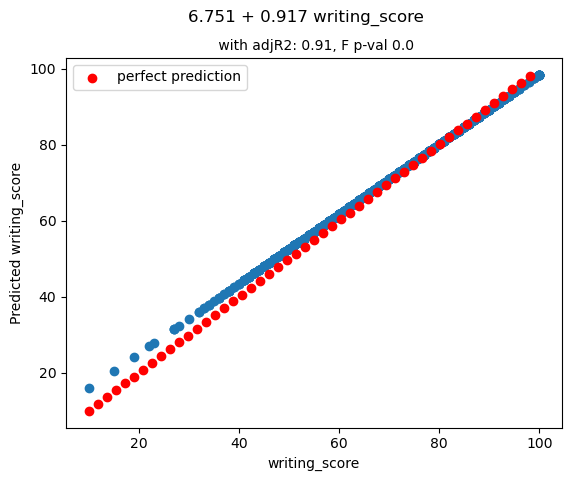

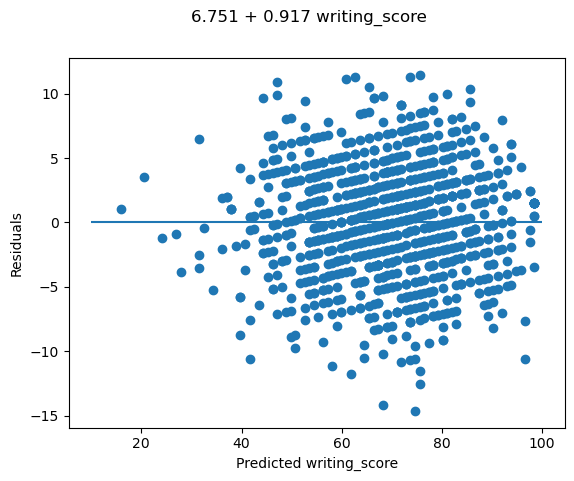

In [20]:
ABPPY7StatTests.mult_reg(model1, full_df['writing_score'])

By running a single regression on the continuous variables of writing scores to see how they affect reading scores, we found that there was an R-squared of .911, showing a very heavy correlation between both scores. We saw on the plot that reading scores are positively correlated with the writing scores, and a student who produced scores one on will more than likely do well on the writing portion. This would make sense when analyzing the factors that would play into account of the students' success (study habits, resources, internal motivation, etc.), where traits like those would apply to other subjects and, in turn, build strong academic achievement across different subjects from these students. This is to say that by looking at these data, we can make an analysis that students who are strong writers tend to also be strong readers when measured through standardized tests. 

RQ 2 : How much better do students do if they are in a prep course?

The groups are no and yes

This is a test of equal variances with Ho: The variances are equal
The t test statistic is 3.215 and the p-value is 0.073
Conclusion: Fail to Reject Ho: We can't reject that the variances are the same

This is a Two-Sample t test (assuming equal variances) of equal means with Ho: The group means are equal
The t test statistic is -8.391 and the p-value is 0.0
Conclusion: Reject Ho: The means are not equal


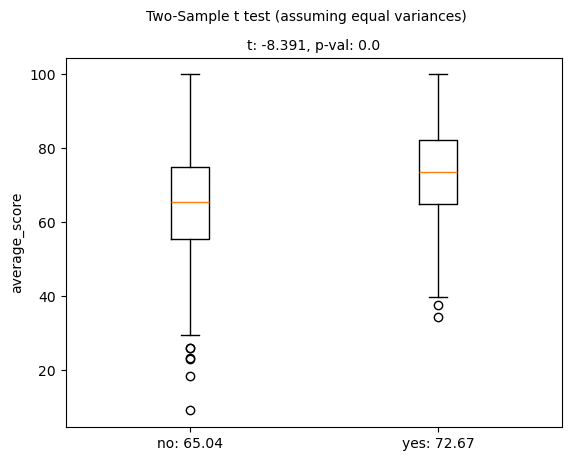

In [41]:
ABPPY7StatTests.MeansTest(full_df, 'test_preparation_course', 'average_score')

When running a test of equal variances, we found that we failed to reject the null hypothesis showing us that we do not have enough evidence to state that the variance in the groups is enough to not be able to say they aren’t equal. We then did a two-sample t-test of equal means with the assumption of equal variance as per the first test. We then found a rejection of the null hypothesis, as we found that there is a significant difference in the average scores of students who did prep courses as opposed to students who did not. We could imagine that the curriculum being taught in this prep course has some materials that help students perform better on these exams. We can, with this data, say that the thesis test preparation course is significantly improving the scores. 

RQ 3 : What is the hypothetically best conditions for a student to score?

In [49]:
model2 = ols("average_score ~  gender + race_ethnicity + parental_level_of_education + lunch + test_preparation_course	", data=full_df).fit()
model2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:          average_score   R-squared:                       0.242
Model:                            OLS   Adj. R-squared:                  0.233
Method:                 Least Squares   F-statistic:                     26.30
Date:                Wed, 18 Mar 2026   Prob (F-statistic):           7.53e-52
Time:                        08:43:11   Log-Likelihood:                -3937.0
No. Observations:                1000   AIC:                             7900.
Df Residuals:                     987   BIC:                             7964.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
====================================================================================================================
                                                       coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------------
Intercept                                           59.3018      1.718     34.527      0.000      55.931      62.672
race_ethnicity[T.group B]                            1.5295      1.612      0.949      0.343      -1.633       4.692
race_ethnicity[T.group C]                            2.3857      1.509      1.581      0.114      -0.576       5.347
race_ethnicity[T.group D]                            5.1262      1.540      3.329      0.001       2.104       8.148
race_ethnicity[T.group E]                            6.9285      1.708      4.056      0.000       3.577      10.280
parental_level_of_education[T.bachelor's degree]     2.5360      1.424      1.781      0.075      -0.258       5.330
parental_level_of_education[T.high school]          -5.1721      1.230     -4.206      0.000      -7.585      -2.759
parental_level_of_education[T.master's degree]       4.0921      1.838      2.227      0.026       0.486       7.698
parental_level_of_education[T.some college]         -0.9277      1.182     -0.785      0.433      -3.248       1.392
parental_level_of_education[T.some high school]     -4.5403      1.264     -3.592      0.000      -7.021      -2.060
gender                                              -3.7244      0.795     -4.682      0.000      -5.285      -2.163
lunch                                                8.7751      0.827     10.605      0.000       7.151      10.399
test_preparation_course                              7.6388      0.830      9.201      0.000       6.010       9.268
==============================================================================
Omnibus:                       12.570   Durbin-Watson:                   2.043
Prob(Omnibus):                  0.002   Jarque-Bera (JB):               12.914
Skew:                          -0.274   Prob(JB):                      0.00157
Kurtosis:                       2.897   Cond. No.                         12.0
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [50]:
model3 = ols("average_score ~  gender  + parental_level_of_education + lunch + test_preparation_course	", data=full_df).fit()
model3.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:          average_score   R-squared:                       0.220
Model:                            OLS   Adj. R-squared:                  0.214
Method:                 Least Squares   F-statistic:                     34.98
Date:                Wed, 18 Mar 2026   Prob (F-statistic):           6.63e-49
Time:                        08:43:12   Log-Likelihood:                -3951.3
No. Observations:                1000   AIC:                             7921.
Df Residuals:                     991   BIC:                             7965.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
====================================================================================================================
                                                       coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------------
Intercept                                           62.5960      1.121     55.852      0.000      60.397      64.795
parental_level_of_education[T.bachelor's degree]     2.3897      1.440      1.659      0.097      -0.437       5.216
parental_level_of_education[T.high school]          -5.5779      1.241     -4.493      0.000      -8.014      -3.142
parental_level_of_education[T.master's degree]       4.4827      1.854      2.418      0.016       0.845       8.120
parental_level_of_education[T.some college]         -0.8461      1.195     -0.708      0.479      -3.191       1.498
parental_level_of_education[T.some high school]     -4.9329      1.271     -3.881      0.000      -7.427      -2.439
gender                                              -3.6460      0.802     -4.549      0.000      -5.219      -2.073
lunch                                                8.9821      0.836     10.742      0.000       7.341      10.623
test_preparation_course                              7.7082      0.838      9.199      0.000       6.064       9.353
==============================================================================
Omnibus:                       10.833   Durbin-Watson:                   2.070
Prob(Omnibus):                  0.004   Jarque-Bera (JB):               11.079
Skew:                          -0.251   Prob(JB):                      0.00393
Kurtosis:                       2.885   Cond. No.                         8.49
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [47]:
model4 = ols("average_score ~  gender+ lunch + test_preparation_course	", data=full_df).fit()
model4.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:          average_score   R-squared:                       0.172
Model:                            OLS   Adj. R-squared:                  0.169
Method:                 Least Squares   F-statistic:                     68.91
Date:                Wed, 18 Mar 2026   Prob (F-statistic):           1.70e-40
Time:                        08:41:40   Log-Likelihood:                -3981.4
No. Observations:                1000   AIC:                             7971.
Df Residuals:                     996   BIC:                             7990.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
===========================================================================================
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                  61.1695      0.850     71.986      0.000      59.502      62.837
gender                     -3.9587      0.823     -4.813      0.000      -5.573      -2.345
lunch                       8.8598      0.859     10.314      0.000       7.174      10.545
test_preparation_course     7.8063      0.857      9.106      0.000       6.124       9.488
==============================================================================
Omnibus:                       10.169   Durbin-Watson:                   2.095
Prob(Omnibus):                  0.006   Jarque-Bera (JB):               10.271
Skew:                          -0.248   Prob(JB):                      0.00588
Kurtosis:                       3.022   Cond. No.                         3.88
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

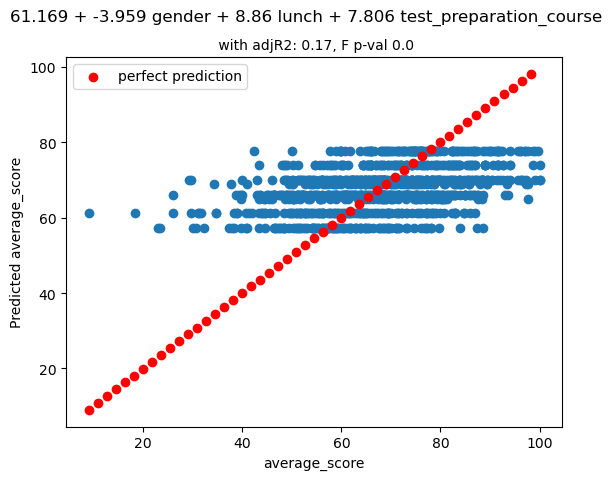

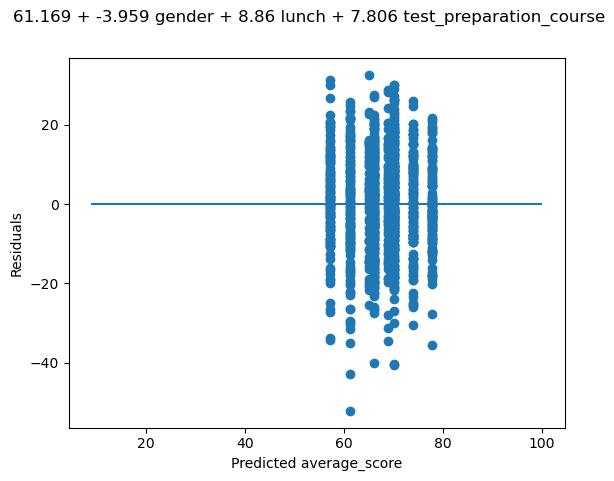

In [51]:
ABPPY7StatTests.mult_reg(model4, full_df['average_score'])

This final question is a culmination of that data to see what factors play into a student's success. I thought that the best way to complete this would be through a multiple regression to see what factors are contributing to it, what isn’t important, and build conclusions based on that. This started with the first model, which included each one of the factors in the regression. I from there began working on a backward elimination of the factors from there, starting with the ethnicity, which had groups with a P>t higher than .05, meaning that I took out that entire group. From that, I did the same with the parents' education level, which also had p>t greater than .05. This left me with a backwards regression model, which included the factors of gender, free lunch, and test prep course. Gender showed that if the student was a male, they were more likely to score less, lunch showed that if a student had free lunch, they would score better than a student without it, and test preparation showed that if a student took a course, they would score better. To answer the question, a female student on free lunch who has done the test prep course, be they hypothetically the best student to score on the exam. The large caveat to this model is the R Squared of .169, showing that even with these factors, there is no strong correlation to the variable, as in the scatter plot, we see a cloud of points surrounding the line, slightly going up, but still fairly spread out. This is to say that there would still not be enough evidence to accurately predict that to be the hypothetically more successful student. 

Conclusion

As we conclude this analysis of this data, we find off of our research questons some things. Success across subjects is something we see where students who can produce results in one area will be likely ot produce similarly in other areas. This is due to the transferable skills in studying and how the student themselves is able to build off one subject into another. That is to say that academic habits would be able to move between different areas, leading to continued success between subjects. Then we were able to see that the test preparation scores created different means between the groups, with those who did the course around 12 points higher than the others. This showed that those with that course tended to score better. At the end, we then ran a backward multiple regression to find variables that would predict higher scores. The variables that were found to correlate with the model were those of gender, free lunch, and test preparation. This led to a model with a weak correlation, where there was still plenty of variance around the line of best fit. The main point we found from this data is that test preparation helps students perform better, and that they tend to do better in reading if they are doing well in writing. Some applied recommendations would be to begin implementing this test preparation course with other students to see greater success across more students. We can also conclude that ethnicity doesn't play any role in success, meaning that children of all different backgrounds are all capable of success. 